In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

import time, joblib
from statsmodels.tsa.stattools import adfuller
from sklearn.ensemble import RandomForestRegressor
from src import data, features as F, models as M, evaluate as E, hybrid as H
dengue, weather = data.load_dengue_clean(), data.load_weather_weekly()
cfg = F.load_feature_config(); num = cfg["numeric_features"]; feats = num + cfg["categorical_features"]

In [2]:
series = {}
for which in ["National", "Colombo"]:
    d, w = H.series_frame(dengue, weather, which)
    d = d.sort_values("start_date").reset_index(drop=True)
    y_log = pd.Series(np.log1p(d.cases.to_numpy()), index=d.start_date)
    ytr = y_log[(d.year <= config.TRAIN_END_YEAR).to_numpy()]

    adf_p = adfuller(ytr.dropna())[1]                    # H0: series has a unit root (needs differencing)
    d_ord = 0 if adf_p < 0.05 else 1
    g1 = H.select_sarima(ytr.to_numpy(), orders=[(p, d_ord, q) for p in range(3) for q in range(3)])
    best_order = tuple(g1.iloc[0]["order"])
    g2 = H.select_sarima(ytr.to_numpy(), orders=[best_order],
                         seasonal_orders=[(0, 0, 0, 0), (1, 0, 0, 52), (1, 0, 1, 52)])
    best_seasonal = tuple(g2.iloc[0]["seasonal_order"])
    t0 = time.time(); res = H.fit_sarima(ytr.to_numpy(), best_order, best_seasonal); fit_s = time.time() - t0
    series[which] = dict(d=d, w=w, y_log=y_log, res=res, order=best_order, seasonal=best_seasonal, fit_s=fit_s)
    print(f"{which}: ADF p = {adf_p:.4f} -> d = {d_ord} | best (p,d,q) by AIC = {best_order} "
          f"(AIC {g1.iloc[0]['aic']:.1f}) | seasonal = {best_seasonal} (AIC {g2.iloc[0]['aic']:.1f})")
    display(g2[["order", "seasonal_order", "aic"]].round(1))

National: ADF p = 0.0157 -> d = 0 | best (p,d,q) by AIC = (1, 0, 1) (AIC 328.5) | seasonal = (1, 0, 1, 52) (AIC 291.5)


,order,seasonal_order,aic
0,"(1, 0, 1)","(1, 0, 1, 52)",291.5
1,"(1, 0, 1)","(1, 0, 0, 52)",295.4
2,"(1, 0, 1)","(0, 0, 0, 0)",328.5


Colombo: ADF p = 0.0084 -> d = 0 | best (p,d,q) by AIC = (1, 0, 1) (AIC 1151.4) | seasonal = (1, 0, 1, 52) (AIC 1084.1)


,order,seasonal_order,aic
0,"(1, 0, 1)","(1, 0, 1, 52)",1084.1
1,"(1, 0, 1)","(1, 0, 0, 52)",1084.9
2,"(1, 0, 1)","(0, 0, 0, 0)",1151.4


In [3]:
rows, store, components = [], [], {}
for which, s in series.items():
    sarima_log = pd.Series(H.one_step_predictions(s["res"], s["y_log"].to_numpy()), index=s["y_log"].index)
    panel = H.RFSarimaHybrid.add_residual_lags(F.build_panel(s["d"], s["w"]), sarima_log, s["y_log"])
    sp = F.split_panel(panel)
    tr, te = sp["train"], sp["test"]
    tr_h = tr[tr.target_date >= s["d"].start_date.min() + pd.Timedelta(weeks=52)]

    t0 = time.time(); hyb = H.RFSarimaHybrid(num).fit(tr_h); hyb_s = time.time() - t0
    rf_alone = M.make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                                     n_jobs=-1, random_state=config.RANDOM_STATE), cfg)
    rf_alone, rf_s = M.fit_timed(rf_alone, tr, feats)

    preds = {"Naive (last week)": te.naive_pred.to_numpy(),
             "SARIMA alone": np.expm1(te.sarima_pred.to_numpy()),
             "RF alone": rf_alone.predict(te[feats]),
             "Hybrid RF+SARIMA": hyb.predict(te)}
    times = {"Naive (last week)": 0, "SARIMA alone": s["fit_s"], "RF alone": rf_s, "Hybrid RF+SARIMA": s["fit_s"] + hyb_s}
    naive_mae = E.regression_metrics(te.target, preds["Naive (last week)"])["MAE"]
    for m, p in preds.items():
        met = E.regression_metrics(te.target, p)
        rows.append({"series": which, "model": m, **met, "MAE_vs_naive_pct": E.improvement(met["MAE"], naive_mae),
                     "train_time_s": round(times[m], 2)})
    store.append(pd.DataFrame({"series": which, "target_date": te.target_date.to_numpy(), "actual": te.target.to_numpy(),
                               **{m: np.clip(p, 0, None).round(2) for m, p in preds.items()}}))
    components[which] = {"order": s["order"], "seasonal_order": s["seasonal"], "params": s["res"].params,
                         "residual_rf": hyb, "rf_alone": rf_alone}

arima_res = pd.DataFrame(rows)
arima_preds = pd.concat(store, ignore_index=True)
arima_res.to_csv(config.MODELS_DIR / "hybrid_arima_results.csv", index=False)
arima_preds.to_csv(config.MODELS_DIR / "hybrid_arima_predictions.csv", index=False)
M.save_model(components, "rf_sarima_hybrid.joblib")
arima_res.round(3)

saved models/rf_sarima_hybrid.joblib (4.7 MB)


,series,model,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,train_time_s
0,National,Naive (last week),210.674,411.618,0.863,14.078,0.000,0.00
1,National,SARIMA alone,214.840,453.554,0.833,14.247,-1.978,6.82
2,National,RF alone,248.360,522.876,0.778,15.577,-17.888,0.42
3,National,Hybrid RF+SARIMA,202.223,397.791,0.872,13.787,4.012,7.37
4,Colombo,Naive (last week),58.123,94.158,0.814,20.232,0.000,0.00
5,Colombo,SARIMA alone,60.520,113.676,0.728,20.783,-4.124,4.23
6,Colombo,RF alone,62.626,102.729,0.778,23.264,-7.747,0.38
7,Colombo,Hybrid RF+SARIMA,61.978,108.028,0.755,22.445,-6.632,4.67


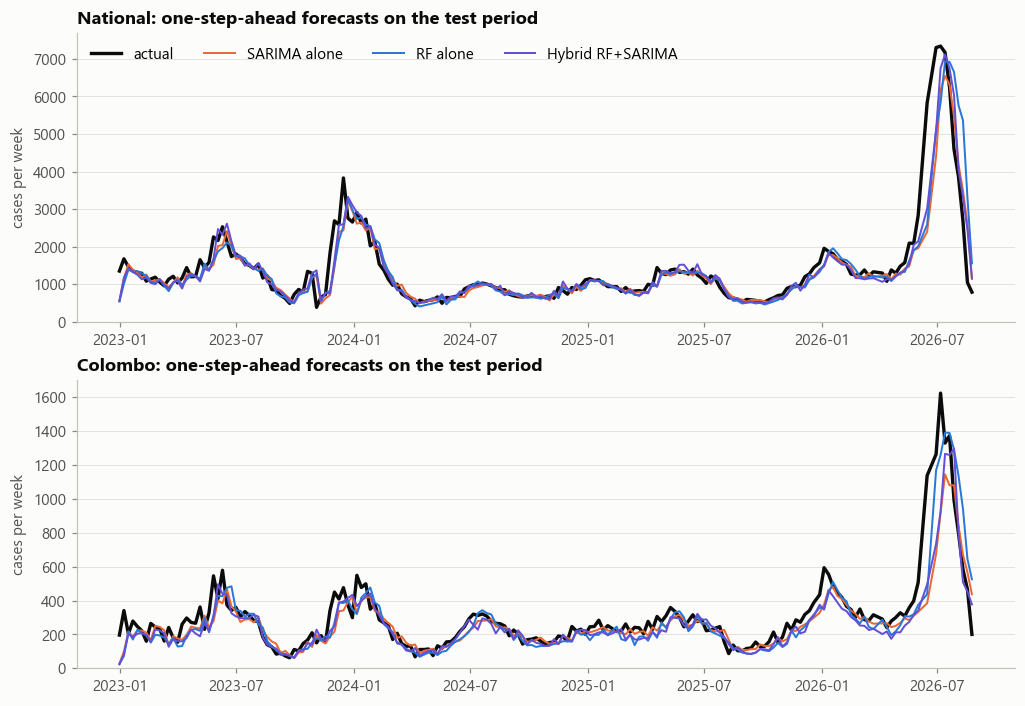

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
for ax, which in zip(axes, ["National", "Colombo"]):
    p = arima_preds[arima_preds.series == which]
    ax.plot(p.target_date, p.actual, color=viz.INK, lw=2.2, label="actual")
    for i, m in enumerate(["SARIMA alone", "RF alone", "Hybrid RF+SARIMA"]):
        ax.plot(p.target_date, p[m], color=[viz.SERIES[1], viz.SERIES[0], viz.SERIES[6]][i], lw=1.3, label=m)
    ax.set_title(f"{which}: one-step-ahead forecasts on the test period"); ax.set_ylabel("cases per week"); ax.set_ylim(0)
axes[0].legend(ncol=4, loc="upper left")
viz.save(fig, "hybrid_rf_sarima_forecasts"); plt.show()

In [5]:
tp = E.load_predictions("test")
col = tp[tp.district == "Colombo"]
reg = M.load_registry()
cmp_models = [E.NAIVE_NAME, reg["bagging_best"]["name"], reg["boosting_best"]["name"], reg["stacking_best"]["name"]]
colombo = pd.DataFrame({m: E.regression_metrics(col.target, col[m]) for m in dict.fromkeys(cmp_models)}).T
colombo = pd.concat([colombo, arima_res[arima_res.series == "Colombo"].set_index("model")[["MAE", "RMSE", "R2", "sMAPE"]]
                     .drop(index="Naive (last week)").rename(index=lambda m: m + " (Colombo only)")])
colombo.sort_values("MAE").round(3)

,MAE,RMSE,R2,sMAPE
Naive (last week),58.123,94.158,0.814,20.232
SARIMA alone (Colombo only),60.520,113.676,0.728,20.783
Extra Trees,60.792,107.155,0.759,21.111
Hybrid RF+SARIMA (Colombo only),61.978,108.028,0.755,22.445
RF alone (Colombo only),62.626,102.729,0.778,23.264
Gradient Boosting,73.085,123.722,0.678,26.327
"Voting (RF+XGB+LGBM+Cat, mean)",73.287,125.873,0.667,26.201


In [6]:
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
rf = M.load_model("random_forest.joblib")
rf_val, rf_test = rf.predict(va[feats]), rf.predict(te[feats])

mlp_params, mlp_cv, mlp_search_s = H.tune_mlp(cfg, tr, feats)
print(f"MLP best CV MAE {mlp_cv:.3f} ({mlp_search_s:.0f}s):", {k.split('__')[-1]: v for k, v in mlp_params.items()})
ann = H.make_mlp_pipeline(cfg).set_params(**mlp_params)
ann, ann_s = M.fit_timed(ann, tr, feats)
ann_val, ann_test = ann.predict(va[feats]), ann.predict(te[feats])
E.record_result("ANN (MLP)", "Neural net", te, ann_test, ann_s, val=va, val_pred=ann_val)
M.save_model(ann, "ann_mlp.joblib"); M.register("ann", "ANN (MLP)", "ann_mlp.joblib")

MLP best CV MAE 13.022 (34s): {'learning_rate_init': 0.001, 'hidden_layer_sizes': (32,), 'alpha': 0.1}


saved models/ann_mlp.joblib (0.1 MB)


saved models/rf_ann_weighted.joblib (0.0 MB)


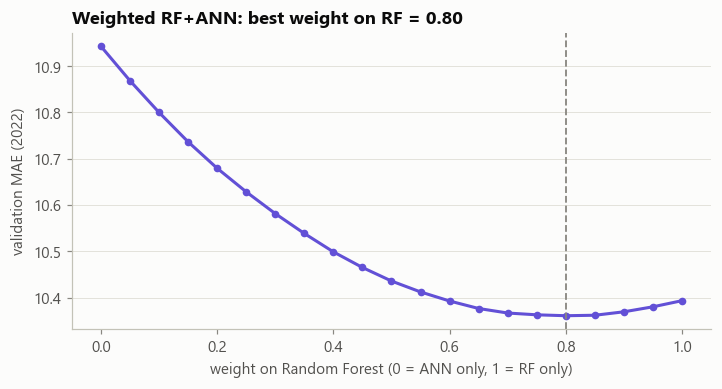

validation MAE  RF only 10.393 | ANN only 10.943 | best mix 10.361
correlation of RF and ANN validation errors: 0.933
diagnostic - test MAE by weight on RF: w=0.0: 17.44, w=0.2: 16.14, w=0.4: 15.09, w=0.6: 14.36, w=0.8: 14.19, w=1.0: 14.52
diagnostic - best weight on test would be 0.80 (MAE 14.19) vs chosen 0.80 (MAE 14.19)


In [7]:
w, curve = H.best_weight(va.target.to_numpy(), rf_val, ann_val)
rf_time = E.load_results().set_index("model").loc["Random Forest", "train_time_s"]
E.record_result("Hybrid RF+ANN (weighted avg)", "Hybrid", te, w * rf_test + (1 - w) * ann_test, rf_time + ann_s,
                val=va, val_pred=w * rf_val + (1 - w) * ann_val)
M.save_model({"weight_rf": w, "rf_file": "random_forest.joblib", "ann_file": "ann_mlp.joblib"}, "rf_ann_weighted.joblib")
M.register("rf_ann_weighted", "Hybrid RF+ANN (weighted avg)", "rf_ann_weighted.joblib", weight_rf=w)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(curve.index, curve.values, color=viz.SERIES[6], marker="o", ms=4)
ax.axvline(w, color=viz.MUTED, ls="--", lw=1.2)
ax.set_xlabel("weight on Random Forest (0 = ANN only, 1 = RF only)"); ax.set_ylabel("validation MAE (2022)")
ax.set_title(f"Weighted RF+ANN: best weight on RF = {w:.2f}")
viz.save(fig, "hybrid_rf_ann_weight"); plt.show()
print(f"validation MAE  RF only {curve.iloc[-1]:.3f} | ANN only {curve.iloc[0]:.3f} | best mix {curve.min():.3f}")
print(f"correlation of RF and ANN validation errors: {np.corrcoef(rf_val - va.target, ann_val - va.target)[0, 1]:.3f}")

# Diagnostic only (NOT used to choose w): what would each weight have scored on the outbreak-heavy test years?
_, test_curve = H.best_weight(te.target.to_numpy(), rf_test, ann_test)
print(f"diagnostic - test MAE by weight on RF: " + ", ".join(f"w={w_:.1f}: {m:.2f}" for w_, m in test_curve.iloc[::4].items()))
print(f"diagnostic - best weight on test would be {test_curve.idxmin():.2f} (MAE {test_curve.min():.2f}) vs chosen {w:.2f} (MAE {test_curve.loc[round(w, 2)]:.2f})")

In [8]:
rf_params, _ = M.load_best_params("Random Forest")
rf2ann = H.RFtoANNRegressor(rf_pipeline=M.build_final("Random Forest", rf_params, cfg),
                            ann_pipeline=H.make_mlp_pipeline(cfg, extra_features=["rf_log_pred"]).set_params(**mlp_params))
rf2ann, r2a_s = M.fit_timed(rf2ann, tr, feats)
E.record_result("Hybrid RF->ANN (RF as input)", "Hybrid", te, rf2ann.predict(te[feats]), r2a_s,
                val=va, val_pred=rf2ann.predict(va[feats]))
# its RF part is identical to models/random_forest.joblib (same data, params and seed), so only the ANN part is saved
M.save_model(rf2ann.ann_, "rf_to_ann_ann_part.joblib")
M.register("rf_to_ann", "Hybrid RF->ANN (RF as input)", "rf_to_ann_ann_part.joblib", rf_file="random_forest.joblib")

saved models/rf_to_ann_ann_part.joblib (0.1 MB)


In [9]:
show = ["Naive (last week)", "Random Forest", "ANN (MLP)", "Hybrid RF+ANN (weighted avg)", "Hybrid RF->ANN (RF as input)"]
E.results_table().set_index("model").loc[show, ["family", "val_MAE", "MAE", "RMSE", "R2", "MAE_normal", "MAE_outbreak",
                                                 "MAE_vs_naive_pct", "train_time_s"]].round(3)

,family,val_MAE,MAE,RMSE,R2,MAE_normal,MAE_outbreak,MAE_vs_naive_pct,train_time_s
model,,,,,,,,,
Naive (last week),Baseline,11.547,14.949,37.586,0.867,7.432,21.062,0.000,0.00
Random Forest,Bagging,10.393,14.520,37.472,0.868,6.073,21.389,2.874,8.49
ANN (MLP),Neural net,10.943,17.440,65.867,0.593,6.891,26.020,-16.664,1.84
Hybrid RF+ANN (weighted avg),Hybrid,10.361,14.190,36.894,0.872,6.004,20.847,5.077,10.33
Hybrid RF->ANN (RF as input),Hybrid,10.771,16.377,53.631,0.730,6.452,24.448,-9.549,26.97
